# 03 · SBOM generator accuracy (E1 — real pilot run) and scanner agreement (E2 — synthetic)
**Supports:** RQ4, Annex I Part II(1), traceability metric *SBOM completeness*.

**E1 pilot (real):** run on 17 Oct 2026 in a sandbox with three generators that were installable offline (cdxgen 12.8.6, cyclonedx-py 7.5.0, cyclonedx-npm 6.0.1) against three fixtures. Ground truth = the package manager's *installed* set (`pip freeze` in the venv, `npm ls --all`); the `c-vendored` fixture is a hand-curated synthetic case (vendored zlib header + Conan manifest).
Syft and Trivy are in the runner but could not be installed in the sandbox; run `experiments/e1_sbom_benchmark/run_e1.sh` in your environment to add them.

**E2 (synthetic):** the scanner JSON files are constructed to exercise the analysis; CVE IDs are real advisories for those package versions, but which scanner reports what is invented.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from crasme import sbom, vulns
E1 = ROOT/'experiments'/'e1_sbom_benchmark'; E2 = ROOT/'experiments'/'e2_scanner_agreement'/'synthetic'

In [2]:
runs = pd.read_csv(E1/'pilot-results'/'runs.csv')
rows = []
for _, run in runs.iterrows():
    truth = sbom.load_ground_truth(E1/'fixtures'/run.fixture/'ground_truth.csv')
    found, meta = sbom.load_sbom(E1/'pilot-results'/pathlib.Path(run.output).name)
    v = sbom.accuracy(found, truth); n = sbom.accuracy(found, truth, 'name')
    rows.append({'fixture': run.fixture, 'generator': f'{run.generator} ({run['mode']})', 'version': run.tool_version,
                 'format': meta['format'], 'truth_n': len(truth), 'found_n': len(found),
                 'precision': v['precision'], 'recall': v['recall'], 'f1': v['f1'], 'name_recall': n['recall'], 'seconds': run.seconds})
e1 = pd.DataFrame(rows); e1

,fixture,generator,version,format,truth_n,found_n,precision,recall,f1,name_recall,seconds
0,c-vendored,cdxgen (auto),12.8.6,CycloneDX 1.7,2,1,1.000,0.500,0.667,0.500,1.835
1,node-app,cdxgen (auto),12.8.6,CycloneDX 1.7,70,70,1.000,1.000,1.000,1.000,2.441
2,node-app,cyclonedx-npm (installed),6.0.1,CycloneDX 1.6,70,70,1.000,1.000,1.000,1.000,1.369
3,py-app,cdxgen (auto),12.8.6,CycloneDX 1.7,12,13,0.923,1.000,0.960,1.000,2.502
4,py-app,cyclonedx-py (requirements),7.5.0,CycloneDX 1.6,12,4,1.000,0.333,0.500,0.333,2.256
5,py-app,cyclonedx-py (environment),7.5.0,CycloneDX 1.6,12,13,0.923,1.000,0.960,1.000,3.766


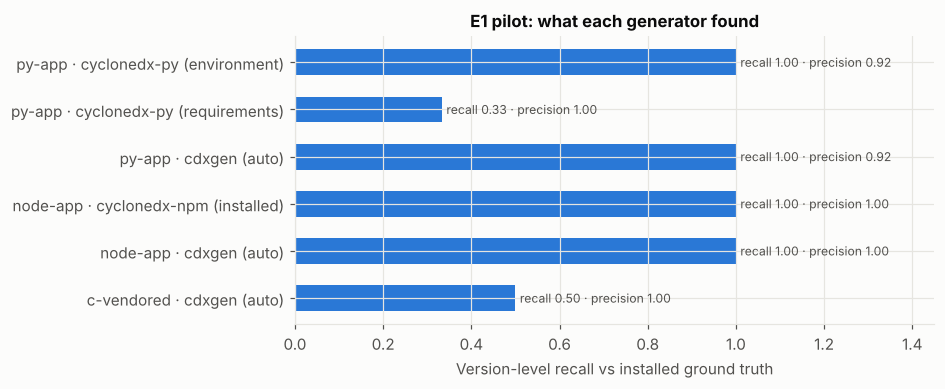

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
lab = e1.fixture + ' · ' + e1.generator
y = np.arange(len(e1))
ax.barh(y, e1.recall, color=plotting.SERIES[0], height=0.55)
for i, (rc, pr) in enumerate(zip(e1.recall, e1.precision)):
    ax.text(rc + 0.01, i, f'recall {rc:.2f} · precision {pr:.2f}', va='center', fontsize=8, color=plotting.INK2)
ax.set_yticks(y, lab); ax.set_xlim(0, 1.45); ax.set_xlabel('Version-level recall vs installed ground truth'); ax.set_title('E1 pilot: what each generator found'); plt.show()

In [4]:
for _, run in runs.iterrows():
    truth = sbom.load_ground_truth(E1/'fixtures'/run.fixture/'ground_truth.csv')
    found, _ = sbom.load_sbom(E1/'pilot-results'/pathlib.Path(run.output).name)
    d = sbom.diff_report(found, truth)
    if d['missing'] or d['extra']:
        print(f'{run.fixture:10s} {run.generator:13s} {run['mode']:12s} missing={d["missing"]} extra={d["extra"]}')

c-vendored cdxgen        auto         missing=['generic:zlib@1.2.11'] extra=[]
py-app     cdxgen        auto         missing=[] extra=['pypi:pip@26.2.1']
py-app     cyclonedx-py  requirements missing=['pypi:certifi@2026.7.22', 'pypi:charset-normalizer@3.5.2', 'pypi:click@8.5.0', 'pypi:idna@3.20', 'pypi:itsdangerous@2.2.0', 'pypi:jinja2@3.1.6', 'pypi:markupsafe@3.0.4', 'pypi:werkzeug@3.1.9'] extra=[]
py-app     cyclonedx-py  environment  missing=[] extra=['pypi:pip@26.2.1']


### E1 pilot findings (n = 3 fixtures — illustrative, not generalisable)
1. **Mode matters more than tool:** `cyclonedx-py requirements` (manifest-only) found 4/12 packages; the same tool in `environment` mode found 12/12. A CI job that SBOMs a manifest instead of the built artefact silently under-reports transitive dependencies — directly relevant to Annex I Part II(1).
2. **Ground-truth definition is a validity threat:** both environment-aware tools listed `pip` itself (counted as a false positive here). The protocol must fix *what counts as a product component* before scoring.
3. **Vendored C code is invisible** to manifest-based generators (`zlib` 1.2.11 missed; Conan dependency found) — the expected weak spot for embedded/IoT SMEs, so E1 must include firmware/C fixtures and binary-analysis tools.
4. Node lockfile-based tools were exact on this small tree.

## E2 · Scanner agreement on the same dependency tree (synthetic outputs)

In [5]:
by = {s: vulns.load_findings(E2/f'node-app.{s}.json', s) for s in ('trivy', 'grype', 'osv-scanner')}
print({s: len(v) for s, v in by.items()})
pd.DataFrame(vulns.agreement_table(by))

{'trivy': 9, 'grype': 8, 'osv-scanner': 7}


,pair,a_only,b_only,both,jaccard
0,grype vs osv-scanner,1,0,7,0.875
1,grype vs trivy,1,2,7,0.700
2,osv-scanner vs trivy,0,2,7,0.778


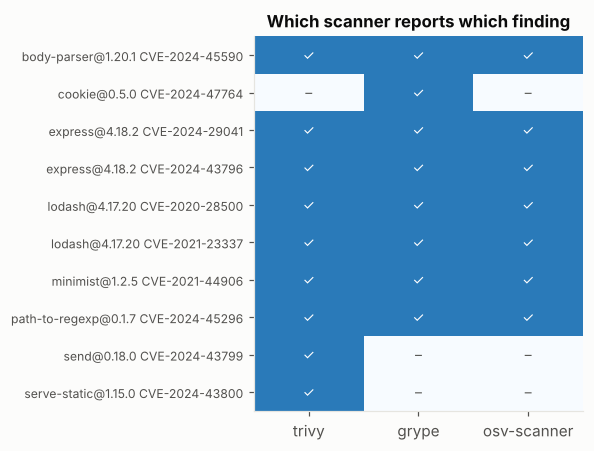

scanner,grype,osv-scanner,trivy
key,,,
cookie@0.5.0 CVE-2024-47764,LOW,NaN,NaN
express@4.18.2 CVE-2024-43796,MEDIUM,,LOW
send@0.18.0 CVE-2024-43799,NaN,NaN,LOW
serve-static@1.15.0 CVE-2024-43800,NaN,NaN,LOW


In [6]:
allkeys = sorted(set().union(*[{f.key for f in v} for v in by.values()]))
mat = pd.DataFrame({s: [k in {f.key for f in v} for k in allkeys] for s, v in by.items()},
                   index=[f'{k[0]} {k[1]}' for k in allkeys]).astype(int)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.imshow(mat.to_numpy(), cmap='Blues', vmin=0, vmax=1.4, aspect='auto')
ax.set_xticks(range(3), mat.columns); ax.set_yticks(range(len(mat)), mat.index, fontsize=8); ax.grid(False)
for (i, j), v in np.ndenumerate(mat.to_numpy()): ax.text(j, i, '✓' if v else '–', ha='center', va='center', fontsize=9, color='white' if v else plotting.INK2)
ax.set_title('Which scanner reports which finding'); plt.tight_layout(); plt.show()
sev = pd.DataFrame([{'key': f'{f.package} {f.vuln_id}', 'scanner': f.scanner, 'severity': f.severity} for v in by.values() for f in v])
sev.pivot(index='key', columns='scanner', values='severity').query('trivy != grype')

**E2 analysis plan (real data):** union of findings → expert adjudication sample (true/false positive, reachable or not) → per-scanner precision/recall against adjudicated set; severity disagreement rate; time-to-triage per finding with/without VEX. Consensus (≥2 scanners) is a triage heuristic only, never ground truth.